# Figure 7 · Where does shape recovery improve?

**Question:** How does performance depend on input quality and galaxy properties?

**Status:** legacy validation preview using existing, predeclared bins and
paired spatial-block intervals. This notebook does not optimize bins to improve
the apparent result. Success populations differ between bins and are counted.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v01'

In [2]:
FIGSIZE = (8.5, 5.6)
analysis = ROOT / 'runs/validation-shapes-full50-best'
provenance = completed_evaluation(analysis)
report = read_json(analysis / 'report.json')
properties = [('nisp_weighted_snr_proxy', 'NISP weighted S/N proxy'),
              ('ACS_F814W_MAG', 'ACS F814W magnitude'),
              ('ez_z_phot', 'Photometric redshift')]
for key, title in properties:
    display(pd.DataFrame([dict(property=title, interval=r['range'], total=r['objects'],
        common_successes=r['common_successes'], eligible=r['reference_baselines_eligible'],
        sr_failures_on_eligible=r['sr_failures_on_eligible']) for r in report['bins'][key]]))

,property,interval,total,common_successes,eligible,sr_failures_on_eligible
0,NISP weighted S/N proxy,"[-inf, 5)",626,240,244,4
1,NISP weighted S/N proxy,"[5, 10)",547,457,457,0
2,NISP weighted S/N proxy,"[10, 20)",439,387,387,0
3,NISP weighted S/N proxy,"[20, 50)",371,322,322,0
4,NISP weighted S/N proxy,"[50, inf)",135,117,117,0


,property,interval,total,common_successes,eligible,sr_failures_on_eligible
0,ACS F814W magnitude,"[-inf, 22)",363,308,308,0
1,ACS F814W magnitude,"[22, 23)",377,326,326,0
2,ACS F814W magnitude,"[23, 24)",584,494,494,0
3,ACS F814W magnitude,"[24, 25)",794,395,399,4


,property,interval,total,common_successes,eligible,sr_failures_on_eligible
0,Photometric redshift,"[0, 0.5)",579,402,404,2
1,Photometric redshift,"[0.5, 1)",812,608,609,1
2,Photometric redshift,"[1, 2)",584,443,443,0
3,Photometric redshift,"[2, 3)",143,70,71,1


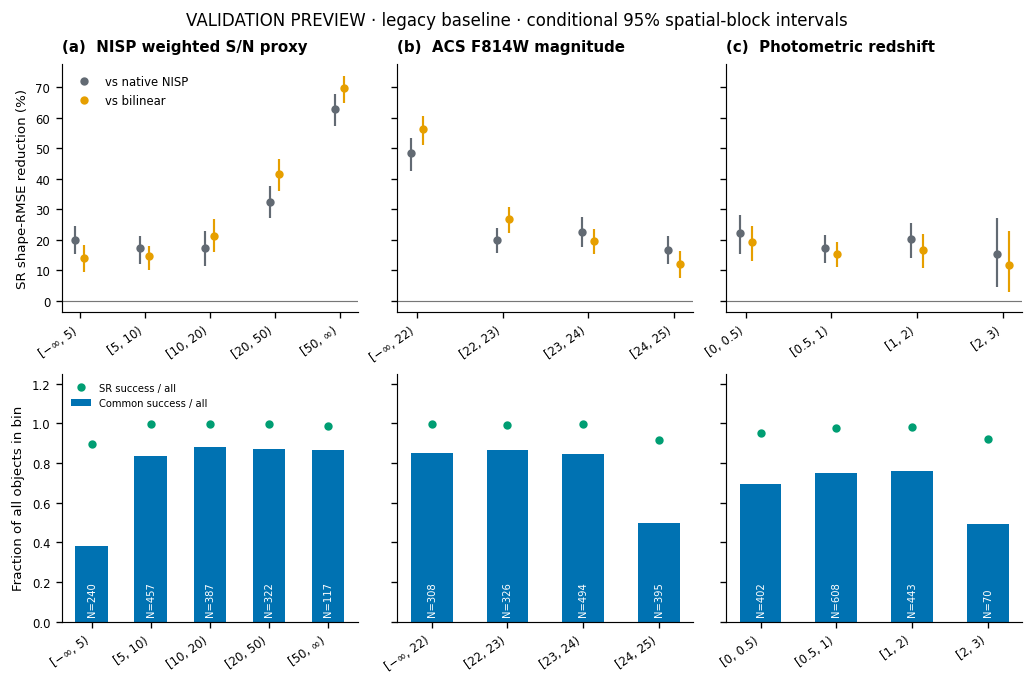

In [3]:
fig, axes = plt.subplots(2, 3, figsize=FIGSIZE, layout='constrained', sharey='row')
for column, (key, title) in enumerate(properties):
    records = report['bins'][key]
    positions = np.arange(len(records))
    for baseline, offset in [('native', -.07), ('bilinear', .07)]:
        values, lower, upper = [], [], []
        for record in records:
            result = record.get('methods', {}).get(baseline, {}).get('sr_comparison', {})
            values.append(result.get('improvement_percent', np.nan))
            interval = result.get('ci95_percent') or [np.nan, np.nan]
            lower.append(interval[0]); upper.append(interval[1])
        # Draw intervals independently of the point; no symmetric-error assumption.
        axes[0,column].vlines(positions+offset, lower, upper, color=COLORS[baseline], lw=1.3)
        axes[0,column].plot(positions+offset, values, 'o', color=COLORS[baseline],
                           ms=4, label='vs ' + ('native NISP' if baseline == 'native' else 'bilinear'))
    axes[0,column].axhline(0, color='#777777', lw=.7)
    panel(axes[0,column], chr(97+column), title)
    total = np.array([r['objects'] for r in records])
    common = np.array([r['common_successes'] for r in records])
    sr_success = np.array([r['success_counts']['sr'] for r in records])
    axes[1,column].bar(positions, common/total, color=COLORS['legacy'], width=.55,
                      label='Common success / all')
    axes[1,column].plot(positions, sr_success/total, 'o', ms=4, color=COLORS['direct5'], label='SR success / all')
    for x, n in zip(positions, common): axes[1,column].text(x, .04, f'N={n}', ha='center', fontsize=6, rotation=90, color='white')
    axes[1,column].set_ylim(0, 1.25)
    for row in range(2):
        axes[row,column].set_xticks(positions, [r['range'].replace('-inf','−∞').replace('inf','∞') for r in records], rotation=35, ha='right')
axes[0,0].set_ylabel('SR shape-RMSE reduction (%)')
axes[1,0].set_ylabel('Fraction of all objects in bin')
axes[0,0].legend(frameon=False); axes[1,0].legend(frameon=False, loc='upper left', fontsize=6)
fig.suptitle('VALIDATION PREVIEW · legacy baseline · conditional 95% spatial-block intervals', fontsize=10)
plt.show()

In [4]:
paths = export(fig, f'fig07_shape_dependence_{VERSION}', '07_shape_dependence.ipynb',
    [analysis/'report.json', analysis/'provenance.json'],
    dict(figsize=FIGSIZE, properties=[key for key, _ in properties], bins='predeclared saved bins',
         intervals='paired spatial-block percentile intervals; conditional on this field'),
    status='legacy-only validation preview')

Exported: fig07_shape_dependence_v01.pdf, fig07_shape_dependence_v01.svg, fig07_shape_dependence_v01.png


## Working caption and review choices

Dependence of observed-shape recovery on NISP weighted S/N, optical magnitude
and photometric redshift. Positive values denote lower SR component RMSE than
the named baseline, with methods compared on the same successful galaxies
within each bin. Intervals resample spatial blocks. The lower panels retain
the measurement coverage and number of common successes.

- S/N is a weighted proxy and ignores correlated noise; label it explicitly.
- Add size only after fixing a defensible angular-size definition.
- Consider one main-text panel and move the remaining properties to an appendix.
- Avoid comparing percentages between bins without their populations/counts.
- Repeat this contract across final models rather than rebinning each model.